# [S II] ratio distributions split by intrinsic [N II] dispersion - 2026-11-03

Compare low- and high-dispersion **spaxels within SF and NSF selections**, with
Pre-peak, Close-to-peak and Post-peak stages overlaid. This is a new, standalone
verification notebook derived from cell 12 and the selection helpers of
`20261027_check_SII_doublet_ratio_SF_NSF_by_stage.ipynb` and
`20261027_check_intrinsic_NII6583_dispersion_SF_NSF_by_stage.ipynb`.
The source notebooks and FITS products are read only.

**Split requested: separate SF and NSF medians.** For each category, pool all
finite positive intrinsic [N II] dispersions across included products and stages,
before requiring [S II] detection, and take the spaxel-weighted median. Use that
one category-specific threshold for every stage and product. Low is strictly
below the median; high includes equality. Ties and [S II] selection mean the
plotted groups need not have equal counts. These are spaxel groups, not a
division of whole galaxies. The medians are empirical dividers, not physical
transition velocities. They are fixed during the product bootstrap; bands
are conditional on these estimated thresholds.

Intrinsic dispersion is `sqrt(NII6583_SIGMA**2 - NII6583_SIGMA_CORR**2)` in km/s.
Nonfinite or nonpositive squared differences are unresolved/invalid and excluded,
not set to zero. As in the source, no added [N II] flux S/N cut or dispersion
ceiling is used. The ratio is corrected `SII6716_FLUX_CORR/SII6730_FLUX_CORR`.
Both lines must pass the source raw flux/error, CUT_SN and NOISE gates and have
finite positive corrected flux. The plotted parent is the intersection of valid
[N II] dispersion and detected [S II] doublet in each SF/NSF category.

Keep source inclination <80 degrees, SNR_POSTFIT >25, MASK==0, finite local
stellar surface density and gas BIN_ID. SF requires finite HII SFR, EW(Halpha)>6 A,
and finite positive intrinsic Halpha dispersion <45 km/s. Balmer non-detections
are excluded; NSF is the remaining usable population. The Halpha-based SF cut
can affect the [N II] dispersion comparison. There is no radius or new mass cut.
NGC4567_8 remains one product/bootstrap unit.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from astropy.io import fits
from astropy.wcs import WCS
from IPython.display import display

PROJECT_ROOT = Path('/Users/Igniz/Desktop/ICRAR/further')
DATA_ROOT = PROJECT_ROOT / 'v3tk_v7.6.8'
OUTPUT_DIR = PROJECT_ROOT / '20261103_SII_ratio_by_NII_dispersion_assets'
GEOMETRY_PATH = PROJECT_ROOT / 'MAUVE_effective_radii.csv'
CATALOG_PATH = PROJECT_ROOT / 'mauve_master_wiki_newclass.fits'
SNR_POSTFIT_MIN = 25.0
INCLINATION_MAX = 80.0
EW_MIN, SIGMA_MAX = 6.0, 45.0
N_BOOTSTRAP = 10_000
RANDOM_SEED = 42
STAGE_LABELS = {1: 'Pre-peak', 2: 'Close-to-peak', 3: 'Post-peak'}
STAGE_COLORS = {1: '#2166ac', 2: '#1a9850', 3: '#d73027'}
CATEGORIES = ('SF', 'NSF')
SII_SATURATION_RATIO = 1.4323317191084541  # Source-notebook shading guide; no density inversion
# Histogram probabilities per bin, not probability density per unit ratio.
RATIO_HIST_EDGES = np.arange(0.0, 2.0 + 0.0125, 0.025)
RATIO_HIST_X_LIMITS = (1.6, 0.4)  # high ratio to low ratio, as requested
RATIO_HIST_LOG_LIMITS = (-5.0, 0.0)
SAVE_FIGURES = False
mpl.rcParams.update({
    'font.size': 13, 'axes.labelsize': 17, 'xtick.labelsize': 14,
    'ytick.labelsize': 14, 'legend.fontsize': 11, 'figure.dpi': 110,
    'xtick.direction': 'in', 'ytick.direction': 'in',
    'pdf.fonttype': 42, 'ps.fonttype': 42,
})

def save_figure(fig, stem):
    if SAVE_FIGURES:
        OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
        for suffix in ('png', 'pdf'):
            fig.savefig(OUTPUT_DIR / f'{stem}.{suffix}', dpi=200, bbox_inches='tight')


Fontconfig error: No writable cache directories
	/opt/homebrew/var/cache/fontconfig
	/Users/Igniz/.cache/fontconfig
	/Users/Igniz/.fontconfig

Fontconfig error: No writable cache directories
	/opt/homebrew/var/cache/fontconfig
	/Users/Igniz/.cache/fontconfig
	/Users/Igniz/.fontconfig

Fontconfig error: No writable cache directories
	/opt/homebrew/var/cache/fontconfig
	/Users/Igniz/.cache/fontconfig
	/Users/Igniz/.fontconfig



Fontconfig error: No writable cache directories
	/opt/homebrew/var/cache/fontconfig
	/Users/Igniz/.cache/fontconfig
	/Users/Igniz/.fontconfig


Matplotlib is building the font cache; this may take a moment.


In [2]:
def first_existing(folder, names):
    for name in names:
        for p in (folder / name, folder / (name + '.gz')):
            if p.is_file():
                return p
    return None

def read_map(path, name):
    with fits.open(path, memmap=True) as h:
        return np.array(h[name].data, dtype=float), h[name].header.copy()

def check_wcs(reference, other, shape, label):
    a, b = WCS(reference).celestial, WCS(other).celestial
    if not (a.has_celestial and b.has_celestial):
        raise ValueError(f'{label}: missing celestial WCS')
    ny, nx = shape
    x, y = np.array([0, nx-1, 0, nx-1, (nx-1)/2]), np.array([0, 0, ny-1, ny-1, (ny-1)/2])
    sep = a.pixel_to_world(x, y).separation(b.pixel_to_world(x, y)).arcsec
    if not np.isfinite(sep).all() or sep.max() > 0.05:
        raise ValueError(f'{label}: WCS separation {sep} arcsec')

# Authoritative stage/geometry join; combined components must agree in stage.
geometry = pd.read_csv(GEOMETRY_PATH)
with fits.open(CATALOG_PATH) as h:
    master_stage = {str(row['Galaxy']).strip():int(row['class']) for row in h[1].data}
geometry['stage_code'] = geometry.galaxy.map(master_stage)
assert geometry.stage_code.notna().all(), 'Missing master stage for a geometry component'
assert np.array_equal(geometry.stage_code.astype(int),geometry.mauve_infall_stage.astype(int))

In [3]:
# Pure dispersion helpers: independently checked on boundary/unresolved cases.
def intrinsic_dispersion(sigma, correction):
    sigma, correction = np.asarray(sigma, float), np.asarray(correction, float)
    with np.errstate(over='ignore', invalid='ignore'):
        squared = sigma**2 - correction**2
    return np.sqrt(np.where(np.isfinite(squared) & (squared > 0), squared, np.nan))

def dispersion_group_masks(values, threshold):
    values = np.asarray(values, float)
    assert np.isfinite(values).all() and (values > 0).all()
    assert np.isfinite(threshold) and threshold > 0
    low, high = values < threshold, values >= threshold
    assert np.all(low.astype(int) + high.astype(int) == 1)
    return low, high

## Load the unchanged SF/NSF selection and both diagnostics

Inventory and provenance tables identify included/missing products. Counts track
the SF/NSF parent, valid [N II] measurements and joint [N II]+[S II] sample
separately. No profile-only 50/20-spaxel support gate is applied to histograms.

In [4]:
product_meta = {}
for galid, components in geometry.groupby('notebook_product_id'):
    assert components.stage_code.nunique()==1, f'{galid}: inconsistent component stages'
    incl = components.inclination_deg.to_numpy(float)
    product_meta[galid] = dict(stage=int(components.stage_code.iloc[0]),
        inclination=float(incl.max()),
        inclination_ok=bool(np.isfinite(incl).all() and (incl<INCLINATION_MAX).all()))
inventory_rows, count_rows, provenance_rows, samples = [], [], [], []
for folder in sorted(p for p in DATA_ROOT.iterdir() if p.is_dir() and not p.name.endswith('_logs')):
    gal = folder.name  # preserves combined IDs such as NGC4567_8
    paths = {
        'mass': first_existing(folder, [f'{gal}_spatial_binning_maps_further.fits', f'{gal}_SPATIAL_BINNING_maps_further.fits']),
        'gas': first_existing(folder, [f'{gal}_gas_bin_maps_further.fits', f'{gal}_gas_BIN_maps_further.fits']),
        'ew': first_existing(folder, [f'{gal}_proxy_EW_maps_further.fits', f'{gal}_proxy_EW_maps.fits']),
        'sfh': first_existing(folder, [f'{gal}_sfh_maps.fits']),
        'mask': first_existing(folder, [f'{gal}_mask.fits']),
    }
    if gal not in product_meta:
        raise KeyError(f'{gal}: no authoritative inclination/stage metadata')
    meta = product_meta[gal]
    missing = [k for k,v in paths.items() if v is None]
    status = ('excluded: inclination >=80 or unavailable' if not meta['inclination_ok']
              else 'missing: '+', '.join(missing) if missing else 'included')
    inventory_rows.append(dict(galaxy=gal,status=status,stage=meta['stage'],
        inclination=meta['inclination'],**{k:str(v) if v else '' for k,v in paths.items()}))

inventory = pd.DataFrame(inventory_rows)
for record in inventory.loc[inventory.status.eq('included')].itertuples(index=False):
    gal = record.galaxy
    meta = product_meta[gal]
    paths = {key: Path(getattr(record, key)) for key in ('mass', 'gas', 'ew', 'sfh', 'mask')}
    assert meta['inclination'] < 80.0
    mass, mass_hdr = read_map(paths['mass'], 'LOGMASS_SURFACE_DENSITY')
    ew, ew_hdr = read_map(paths['ew'], 'PROXY_EWHA')
    snr_postfit, snr_hdr = read_map(paths['sfh'], 'SNR_POSTFIT')
    with fits.open(paths['gas'], memmap=True) as h:
        hdr = h[0].header.copy()
        gas_hdr = h['BIN_ID'].header.copy()
        arrays = {name: np.array(h[name].data, dtype=float) for name in (
            'BIN_ID', 'LOGSFR_SURFACE_DENSITY_HII', 'LOGSFR_SURFACE_DENSITY_UPPER',
            'LOGSFR_SURFACE_DENSITY', 'HA6562_SIGMA', 'HA6562_SIGMA_CORR',
            'NII6583_SIGMA', 'NII6583_SIGMA_CORR',
            'SII6716_FLUX', 'SII6716_FLUX_ERR', 'SII6716_FLUX_CORR',
            'SII6730_FLUX', 'SII6730_FLUX_ERR', 'SII6730_FLUX_CORR',
            'HA6562_FLUX', 'HA6562_FLUX_ERR', 'HB4861_FLUX', 'HB4861_FLUX_ERR')}
    if any(a.shape != mass.shape for a in [ew, snr_postfit, *arrays.values()]):
        raise ValueError(f'{gal}: map shape mismatch; align explicitly before using')
    check_wcs(mass_hdr, gas_hdr, mass.shape, gal+' mass/gas')
    check_wcs(mass_hdr, ew_hdr, mass.shape, gal+' mass/EW')
    check_wcs(mass_hdr, snr_hdr, mass.shape, gal+' mass/SFH SNR')
    with fits.open(paths['mask']) as h:
        flat_mask = np.asarray(h['MASKFILE'].data['MASK'])
        if flat_mask.size != mass.size:
            raise ValueError(f'{gal}: spatial mask length mismatch')
        spatial_mask = flat_mask.reshape(mass.shape)
    # Mandatory first-stage usability gate: only then define SF, ND, or remaining NSF.
    pre_snr = np.isfinite(mass) & np.isfinite(arrays['BIN_ID']) & (spatial_mask == 0)
    snr_pass = np.isfinite(snr_postfit) & (snr_postfit > SNR_POSTFIT_MIN)
    valid = pre_snr & snr_pass
    assert np.all(snr_postfit[valid] > 25.0)
    assert not np.any(valid & (~np.isfinite(snr_postfit) | (snr_postfit <= 25.0)))
    sn_cut, floor = float(hdr['CUT_SN']), float(hdr['NOISE'])
    assert np.isfinite(sn_cut) and sn_cut > 0 and np.isfinite(floor) and floor > 0
    assert str(hdr['BPTMODE']).lower().strip() == 'both', f'{gal}: unexpected BPTMODE'
    balmer = np.ones(mass.shape, dtype=bool)
    measurable = np.ones(mass.shape, dtype=bool)
    for line in ('HA6562', 'HB4861'):
        f, e = arrays[line+'_FLUX'], arrays[line+'_FLUX_ERR']
        good = np.isfinite(f) & np.isfinite(e) & (e > 0)
        measurable &= good
        with np.errstate(divide='ignore', invalid='ignore'):
            balmer &= good & (f/e >= sn_cut) & (f >= floor)
    # Preserve the source Halpha-based SF/ND/NSF classification.
    ha_sigma2 = arrays['HA6562_SIGMA']**2 - arrays['HA6562_SIGMA_CORR']**2
    ha_sigma = np.sqrt(np.where(np.isfinite(ha_sigma2) & (ha_sigma2 > 0), ha_sigma2, np.nan))
    sfr = arrays['LOGSFR_SURFACE_DENSITY_HII']
    sf = valid & np.isfinite(sfr) & np.isfinite(ew) & (ew > EW_MIN) & np.isfinite(ha_sigma) & (ha_sigma < SIGMA_MAX)
    nd = valid & ~balmer
    nd_upper = arrays['LOGSFR_SURFACE_DENSITY_UPPER']
    assert np.isfinite(nd_upper[nd]).all(), f'{gal}: missing ND SFR upper limits'
    assert np.allclose(nd_upper[nd], arrays['LOGSFR_SURFACE_DENSITY'][nd]), f'{gal}: ND SFR map mismatch'
    assert not np.any(sf & nd), f'{gal}: SF overlaps Balmer ND'
    assert np.all(snr_postfit[sf | nd] > 25.0), f'{gal}: category bypassed strict SNR cut'
    excluded = valid & ~sf & ~nd
    assert int(valid.sum()) == int(sf.sum()+nd.sum()+excluded.sum())
    nsf = excluded
    nsf_upper = arrays['LOGSFR_SURFACE_DENSITY']
    assert np.isfinite(nsf_upper[nsf]).all(), f'{gal}: missing NSF SFR upper-limit proxy'
    assert np.all(snr_postfit[nsf] > 25.0), f'{gal}: NSF bypassed strict SNR cut'
    assert np.array_equal(sf.astype(int)+nd.astype(int)+nsf.astype(int), valid.astype(int))



    doublet_ok = np.ones(mass.shape, dtype=bool)
    fluxes = []
    for line in ('SII6716', 'SII6730'):
        raw, err, corr = (arrays[line + suffix] for suffix in ('_FLUX', '_FLUX_ERR', '_FLUX_CORR'))
        with np.errstate(divide='ignore', invalid='ignore'):
            doublet_ok &= (np.isfinite(raw) & np.isfinite(err) & (err > 0)
                           & (raw / err >= sn_cut) & (raw >= floor)
                           & np.isfinite(corr) & (corr > 0))
        fluxes.append(corr)
    ratio = np.full(mass.shape, np.nan)
    with np.errstate(divide='ignore', invalid='ignore', over='ignore'):
        ratio[doublet_ok] = fluxes[0][doublet_ok] / fluxes[1][doublet_ok]
    doublet_ok &= np.isfinite(ratio) & (ratio > 0)
    count = dict(galaxy=gal, stage=meta['stage'], inclination=meta['inclination'],
                 usable=int(valid.sum()), SF=int(sf.sum()), ND=int(nd.sum()), NSF=int(nsf.sum()))
    provenance_rows.append(dict(galaxy=gal, CUT_SN=sn_cut, NOISE=floor,
        DUSTLAW=hdr.get('DUSTLAW', 'not recorded'), gas_path=str(paths['gas'])))

    dispersion = intrinsic_dispersion(arrays['NII6583_SIGMA'], arrays['NII6583_SIGMA_CORR'])
    dispersion_ok = np.isfinite(dispersion) & (dispersion > 0)
    for category, category_mask in (('SF', sf), ('NSF', nsf)):
        nii_selected = category_mask & dispersion_ok
        joint = nii_selected & doublet_ok
        count['N_NII_' + category] = int(nii_selected.sum())
        count['N_joint_' + category] = int(joint.sum())
        count['N_SII_only_' + category] = int((category_mask & doublet_ok).sum())
        samples.append(dict(galaxy=gal, stage=meta['stage'], category=category,
            nii_dispersion=dispersion[nii_selected].copy(),
            joint_dispersion=dispersion[joint].copy(), ratio=ratio[joint].copy()))
    count_rows.append(count)
    print(f'{gal}: joint SF={count["N_joint_SF"]:,}, NSF={count["N_joint_NSF"]:,}', flush=True)

counts = pd.DataFrame(count_rows)
provenance = pd.DataFrame(provenance_rows)
assert len(counts), 'No complete included products'
assert (counts.usable == counts.SF + counts.ND + counts.NSF).all()
assert counts.inclination.lt(INCLINATION_MAX).all()
for category in CATEGORIES:
    assert (counts['N_joint_' + category] <= counts['N_NII_' + category]).all()
    assert (counts['N_NII_' + category] <= counts[category]).all()
display(inventory[['galaxy', 'stage', 'inclination', 'status']])
display(counts)
display(provenance)
print('Products by stage:', counts.groupby('stage').size().rename(index=STAGE_LABELS).to_dict())

IC3392: joint SF=13,888, NSF=6,512


NGC4064: joint SF=3,273, NSF=26,106


NGC4189: joint SF=80,517, NSF=33,542


NGC4254: joint SF=465,623, NSF=158,798


NGC4293: joint SF=471, NSF=35,773


NGC4294: joint SF=67,512, NSF=50,492


... (20 outputs left out)

,galaxy,stage,inclination,status
0,IC3392,3,68.0,included
1,NGC4064,3,70.0,included
2,NGC4189,1,42.0,included
3,NGC4192,1,83.0,excluded: inclination >=80 or unavailable
4,NGC4222,1,90.0,excluded: inclination >=80 or unavailable
5,NGC4254,1,39.0,included
6,NGC4293,3,67.0,included
7,NGC4294,1,74.0,included
8,NGC4298,2,52.0,included
9,NGC4302,2,90.0,excluded: inclination >=80 or unavailable


,galaxy,stage,inclination,usable,SF,ND,NSF,N_NII_SF,N_joint_SF,N_SII_only_SF,N_NII_NSF,N_joint_NSF,N_SII_only_NSF
0,IC3392,3,68.0,57030,13888,34019,9123,13888,13888,13888,9123,6512,6512
1,NGC4064,3,70.0,128406,3273,91212,33921,3273,3273,3273,33921,26106,26106
2,NGC4189,1,42.0,120917,80671,6234,34012,80671,80517,80517,34012,33542,33542
3,NGC4254,1,39.0,637876,466023,8495,163358,466023,465623,465623,163358,158798,158798
4,NGC4293,3,67.0,253797,471,189926,63400,471,471,471,63400,35773,35773
5,NGC4294,1,74.0,123446,67512,4508,51426,67512,67512,67512,51426,50492,50492
6,NGC4298,2,52.0,232720,138402,51214,43104,138402,134035,134035,43104,34685,34685
7,NGC4321,1,32.0,789734,375302,84777,329655,375302,371493,371493,329655,279081,279081
8,NGC4351,1,48.0,78282,29731,31869,16682,29731,29731,29731,16682,16682,16682
9,NGC4380,3,61.0,233695,56075,126430,51190,56075,34550,34550,51190,22717,22717


,galaxy,CUT_SN,NOISE,DUSTLAW,gas_path
0,IC3392,3.0,20.0,calzetti,/Users/Igniz/Desktop/ICRAR/further/v3tk_v7.6.8...
1,NGC4064,3.0,20.0,calzetti,/Users/Igniz/Desktop/ICRAR/further/v3tk_v7.6.8...
2,NGC4189,3.0,20.0,calzetti,/Users/Igniz/Desktop/ICRAR/further/v3tk_v7.6.8...
3,NGC4254,3.0,20.0,calzetti,/Users/Igniz/Desktop/ICRAR/further/v3tk_v7.6.8...
4,NGC4293,3.0,20.0,calzetti,/Users/Igniz/Desktop/ICRAR/further/v3tk_v7.6.8...
5,NGC4294,3.0,20.0,calzetti,/Users/Igniz/Desktop/ICRAR/further/v3tk_v7.6.8...
6,NGC4298,3.0,20.0,calzetti,/Users/Igniz/Desktop/ICRAR/further/v3tk_v7.6.8...
7,NGC4321,3.0,20.0,calzetti,/Users/Igniz/Desktop/ICRAR/further/v3tk_v7.6.8...
8,NGC4351,3.0,20.0,calzetti,/Users/Igniz/Desktop/ICRAR/further/v3tk_v7.6.8...
9,NGC4380,3.0,20.0,calzetti,/Users/Igniz/Desktop/ICRAR/further/v3tk_v7.6.8...


Products by stage: {'Pre-peak': 8, 'Close-to-peak': 5, 'Post-peak': 13}


## Category medians and low/high histograms

The threshold table reports pre-doublet median samples and the resulting joint
sample counts. Histogram bins are 0.025 wide over [0,2], displayed from 1.6 to
0.4. Ratios beyond the grid/display are retained in denominators and reported.
The source gray guide above 1.4323317191 is retained without excluding points
or converting ratios to density.

In [5]:
thresholds, threshold_rows, histogram_rows = {}, [], []
for category in CATEGORIES:
    all_nii = np.concatenate([s['nii_dispersion'] for s in samples if s['category'] == category])
    if not len(all_nii):
        raise ValueError(f'{category}: no valid NII dispersion for a median split')
    thresholds[category] = float(np.median(all_nii))
    threshold_rows.append(dict(category=category, median_km_s=thresholds[category],
        N_NII_before_SII=len(all_nii),
        N_below_median=int((all_nii < thresholds[category]).sum()),
        N_at_median=int((all_nii == thresholds[category]).sum()),
        N_at_or_above_median=int((all_nii >= thresholds[category]).sum())))
threshold_table = pd.DataFrame(threshold_rows)
display(threshold_table)

for sample in samples:
    values, dispersion = sample['ratio'], sample['joint_dispersion']
    low, high = dispersion_group_masks(dispersion, thresholds[sample['category']])
    selections = {'all': np.ones(len(values), dtype=bool), 'low': low, 'high': high}
    parts = {}
    for group, mask in selections.items():
        v = values[mask]
        hist = np.histogram(v, bins=RATIO_HIST_EDGES)[0]
        below, above = int((v < RATIO_HIST_EDGES[0]).sum()), int((v > RATIO_HIST_EDGES[-1]).sum())
        assert int(hist.sum()) + below + above == len(v)
        parts[group] = hist
        histogram_rows.append(dict(galaxy=sample['galaxy'], stage=sample['stage'],
            category=sample['category'], group=group, hist=hist, N_total=len(v),
            N_parent=len(values), N_below_grid=below, N_above_grid=above,
            N_outside_display=int(((v < min(RATIO_HIST_X_LIMITS)) | (v > max(RATIO_HIST_X_LIMITS))).sum()),
            N_at_threshold=int((dispersion[mask] == thresholds[sample['category']]).sum())))
    assert np.array_equal(parts['all'], parts['low'] + parts['high'])
histograms_by_product = pd.DataFrame(histogram_rows)
for _, panel in histograms_by_product.groupby(['galaxy', 'category']):
    n = panel.set_index('group').N_total
    assert n['all'] == n['low'] + n['high']
display(histograms_by_product.drop(columns='hist'))

,category,median_km_s,N_NII_before_SII,N_below_median,N_at_median,N_at_or_above_median
0,SF,30.873962,2364184,1182076,20,1182108
1,NSF,40.252362,2233856,1116927,9,1116929


,galaxy,stage,category,group,N_total,N_parent,N_below_grid,N_above_grid,N_outside_display,N_at_threshold
0,IC3392,3,SF,all,13888,13888,0,45,2309,0
1,IC3392,3,SF,low,8031,13888,0,29,1432,0
2,IC3392,3,SF,high,5857,13888,0,16,877,0
3,IC3392,3,NSF,all,6512,6512,0,179,2073,0
4,IC3392,3,NSF,low,5762,6512,0,157,1861,0
...,...,...,...,...,...,...,...,...,...,...
151,NGC4698,3,SF,low,4172,4909,0,21,539,0
152,NGC4698,3,SF,high,737,4909,0,0,75,0
153,NGC4698,3,NSF,all,66058,66058,0,3880,19675,0
154,NGC4698,3,NSF,low,33340,66058,0,1316,8963,0


## Separately normalized distributions and whole-product bootstrap

For each stage/category/dispersion group, **equal-galaxy** means the mean of
`N_g,ratio_bin/N_g,group` over products with a nonempty group; **pooled-spaxel**
means summed bin counts divided by summed group counts. Empty products are
excluded only from that group's normalization. Product sets can differ between
low and high groups; the QC table makes this explicit. Zero counts within a
ratio bin contribute zero for otherwise eligible products. This is a distribution
of individual spaxel ratios, not a ratio of summed line fluxes.

The low/high curves are separately normalized shapes and do not add to the
all-sample curve. This differs deliberately from the common-denominator radial
contributions in source cell 12. The all-sample plot uses the same joint parent.

Resample whole products 10,000 times within each stage, sharing multiplicities
across categories, groups and estimators. Recompute each group denominator in
each draw; fixed category medians are not re-estimated. Bars are 16th-84th
percentiles, conditional on thresholds and available measurements, with at least
two nonzero contributing products per ratio bin. They do not propagate line-flux
or dispersion errors, median-estimation uncertainty, or independent-spaxel noise.

In [6]:
def normalized_histogram_bootstrap(histograms, totals, multiplicities, branch='pooled_spaxel'):
    """Bin fractions with pooled-spaxel or equal-product central and bootstrap weights."""
    histograms = np.asarray(histograms, dtype=float)
    totals = np.asarray(totals, dtype=float)
    assert histograms.ndim == 2 and histograms.shape[0] == len(totals)
    assert np.all(histograms >= 0) and np.all(totals >= 0)
    assert np.all(histograms.sum(axis=1) <= totals)
    if branch == 'equal_galaxy':
        eligible = totals > 0
        values = np.divide(histograms, totals[:, None], out=np.zeros_like(histograms),
                           where=totals[:, None] > 0)
        weights = eligible.astype(float)
    elif branch == 'pooled_spaxel':
        values, weights = histograms, totals
    else:
        raise ValueError(f'Unknown distribution estimator: {branch}')
    central = values.sum(axis=0) / weights.sum() if weights.sum() else np.full(histograms.shape[1], np.nan)
    # Direct sums avoid spurious floating-point warnings from the local matmul backend.
    boot_denominator = np.einsum('bg,g->b', multiplicities, weights, optimize=False)
    boot_numerator = np.einsum('bg,gj->bj', multiplicities, values, optimize=False)
    boot = np.divide(boot_numerator, boot_denominator[:, None],
        out=np.full((len(multiplicities), histograms.shape[1]), np.nan), where=boot_denominator[:, None] > 0)
    finite_draws = boot_denominator > 0
    assert np.isfinite(boot[finite_draws]).all()
    assert np.all((boot[finite_draws] >= 0) & (boot[finite_draws] <= 1 + 1e-12))
    return central, boot, finite_draws

In [7]:
distribution_rows, qc_rows = [], []
for stage in (1, 2, 3):
    ids = counts.loc[counts.stage.eq(stage), 'galaxy'].sort_values().to_numpy()
    g = len(ids)
    rng = np.random.default_rng(RANDOM_SEED + 23_000_000 + stage)
    multiplicities = (rng.multinomial(g, np.full(g, 1/g), size=N_BOOTSTRAP)
                      if g else np.empty((N_BOOTSTRAP, 0), dtype=int))
    for category in CATEGORIES:
        for group in ('all', 'low', 'high'):
            panel = histograms_by_product.loc[
                histograms_by_product.stage.eq(stage) & histograms_by_product.category.eq(category)
                & histograms_by_product.group.eq(group)].set_index('galaxy').reindex(ids)
            assert panel.N_total.notna().all()
            hist = np.stack(panel['hist'].to_list()) if g else np.empty((0, len(RATIO_HIST_EDGES)-1))
            totals = panel.N_total.to_numpy(float)
            support, eligible = (hist > 0).sum(axis=0), totals > 0
            tail = panel.N_below_grid.to_numpy(float) + panel.N_above_grid.to_numpy(float)
            for branch in ('equal_galaxy', 'pooled_spaxel'):
                central, boot, finite_draws = normalized_histogram_bootstrap(hist, totals, multiplicities, branch)
                bounds = (np.percentile(boot[finite_draws], [16, 84], axis=0) if finite_draws.any()
                          else np.full((2, hist.shape[1]), np.nan))
                bounds[:, support < 2] = np.nan
                if eligible.any():
                    expected = ((hist[eligible]/totals[eligible, None]).mean(axis=0)
                                if branch == 'equal_galaxy' else hist.sum(axis=0)/totals.sum())
                    tail_probability = ((tail[eligible]/totals[eligible]).mean()
                                        if branch == 'equal_galaxy' else tail.sum()/totals.sum())
                    assert np.allclose(central, expected)
                    assert np.isclose(central.sum() + tail_probability, 1.)
                else:
                    assert np.isnan(central).all() and not finite_draws.any()
                for j, (lo, hi) in enumerate(zip(RATIO_HIST_EDGES[:-1], RATIO_HIST_EDGES[1:])):
                    distribution_rows.append(dict(branch=branch, stage=stage, category=category,
                        group=group, center=(lo+hi)/2, probability=central[j], lo=bounds[0,j], hi=bounds[1,j],
                        N_bin=int(hist[:,j].sum()), N_total=int(totals.sum()),
                        N_products_in_bin=int(support[j]), N_products_normalized=int(eligible.sum()),
                        N_finite_draws=int(finite_draws.sum())))
            qc_rows.append(dict(stage=STAGE_LABELS[stage], category=category, group=group,
                N_total=int(totals.sum()), N_products_normalized=int(eligible.sum()),
                N_products_empty=int((~eligible).sum()), N_in_grid=int(hist.sum()),
                N_below_grid=int(panel.N_below_grid.sum()), N_above_grid=int(panel.N_above_grid.sum()),
                N_outside_display=int(panel.N_outside_display.sum())))
ratio_distributions = pd.DataFrame(distribution_rows)
histogram_qc = pd.DataFrame(qc_rows)
assert (histogram_qc.N_total == histogram_qc.N_in_grid + histogram_qc.N_below_grid + histogram_qc.N_above_grid).all()
assert ratio_distributions.loc[ratio_distributions.N_products_in_bin.lt(2), ['lo', 'hi']].isna().all().all()
assert not ratio_distributions.duplicated(['branch','stage','category','group','center']).any()
display(histogram_qc)
print('Joint-sample partition, both normalizations, histogram tails and bootstrap support verified.')

,stage,category,group,N_total,N_products_normalized,N_products_empty,N_in_grid,N_below_grid,N_above_grid,N_outside_display
0,Pre-peak,SF,all,1412363,8,0,1411557,0,806,66406
1,Pre-peak,SF,low,703718,8,0,703563,0,155,20208
2,Pre-peak,SF,high,708645,8,0,707994,0,651,46198
3,Pre-peak,NSF,all,805528,8,0,798522,0,7006,117509
4,Pre-peak,NSF,low,471395,8,0,469538,0,1857,61052
5,Pre-peak,NSF,high,334133,8,0,328984,0,5149,56457
6,Close-to-peak,SF,all,713550,5,0,713145,0,405,42867
7,Close-to-peak,SF,low,345268,5,0,345196,0,72,12535
8,Close-to-peak,SF,high,368282,5,0,367949,0,333,30332
9,Close-to-peak,NSF,all,457952,5,0,452048,0,5904,78020


Joint-sample partition, both normalizations, histogram tails and bootstrap support verified.


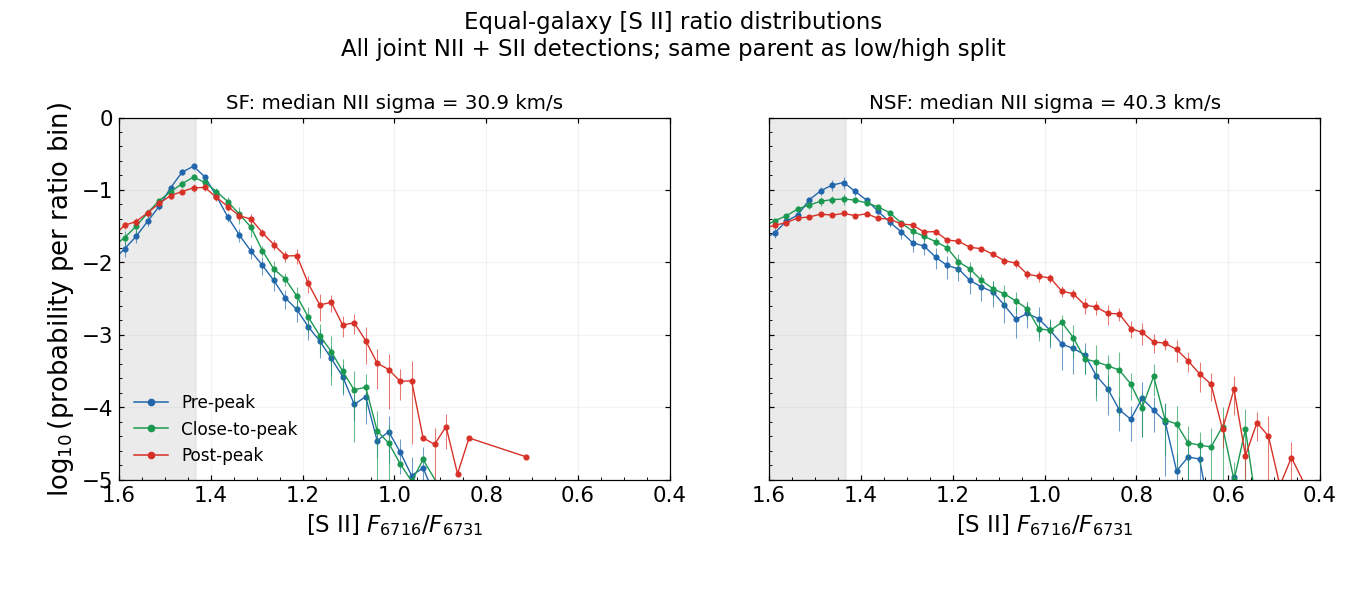

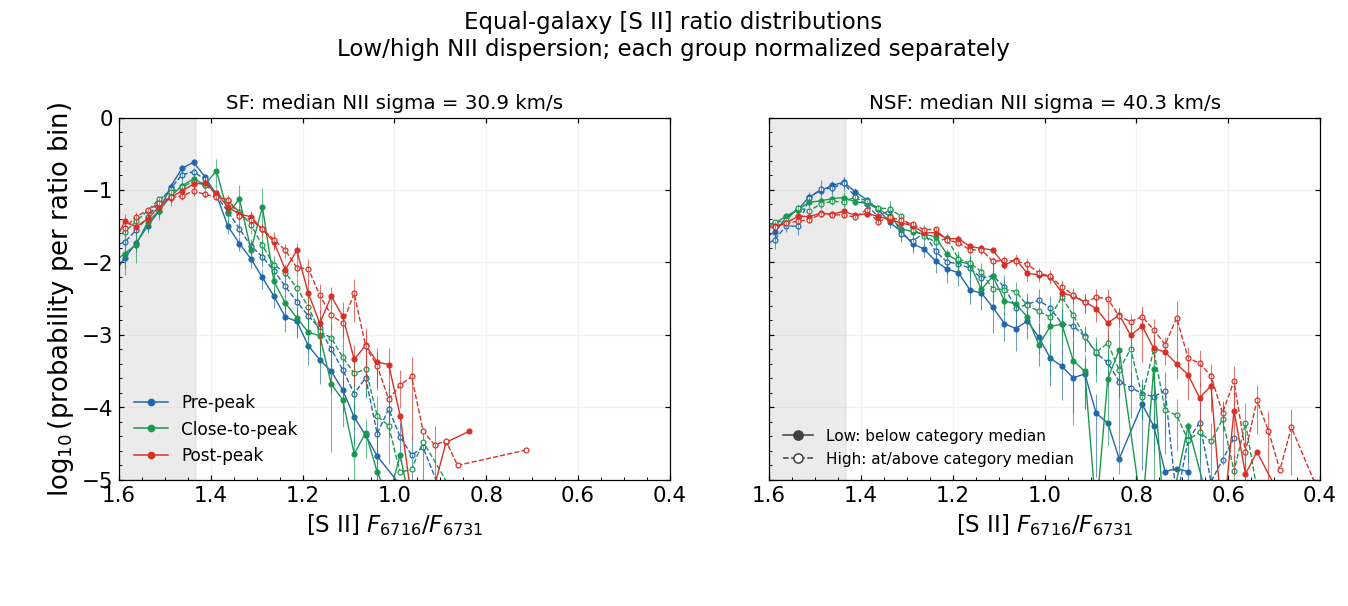

In [8]:
from matplotlib.lines import Line2D

def draw_ratio_distribution(ax, panel, color, filled, linestyle, label=None):
    positive = panel.loc[panel.probability.gt(0)].sort_values('center')
    if positive.empty:
        return
    x = positive.center.to_numpy(float)
    y = np.log10(positive.probability.to_numpy(float))
    ax.plot(x, y, color=color, marker='o', ms=3.2, lw=0.9, ls=linestyle,
            markerfacecolor=color if filled else 'white', markeredgewidth=0.8, label=label)
    band = positive.loc[positive.N_products_in_bin.ge(2) & positive.lo.notna() & positive.hi.gt(0)]
    if len(band):
        floor = 10.0 ** RATIO_HIST_LOG_LIMITS[0]
        lower = np.log10(np.maximum(band.lo.to_numpy(float), floor))
        upper = np.log10(np.maximum(band.hi.to_numpy(float), floor))
        ax.vlines(band.center, lower, upper, color=color, lw=0.7, alpha=0.65)
        zero_bound = band.lo.le(0)
        ax.plot(band.loc[zero_bound, 'center'], np.full(int(zero_bound.sum()), RATIO_HIST_LOG_LIMITS[0]),
                marker='v', ms=3, linestyle='none', color=color, clip_on=False)




def plot_dispersion_split(branch):
    for split in (False, True):
        fig, axes = plt.subplots(1, len(CATEGORIES), figsize=(12, 5.4), sharex=True, sharey=True)
        fig.subplots_adjust(left=0.08, right=0.99, bottom=0.19, top=0.80, wspace=0.18)
        for ax, category in zip(axes, CATEGORIES):
            for stage in (1, 2, 3):
                for group in (('low', 'high') if split else ('all',)):
                    panel = ratio_distributions.loc[ratio_distributions.branch.eq(branch)
                        & ratio_distributions.stage.eq(stage) & ratio_distributions.category.eq(category)
                        & ratio_distributions.group.eq(group)]
                    draw_ratio_distribution(ax, panel, STAGE_COLORS[stage], filled=group != 'high',
                        linestyle='--' if group == 'high' else '-')
            ax.set_title(f'{category}: median NII sigma = {thresholds[category]:.1f} km/s', fontsize=13)
            ax.set_xlim(RATIO_HIST_X_LIMITS)
            ax.set_ylim(RATIO_HIST_LOG_LIMITS)
            ax.axvspan(SII_SATURATION_RATIO, max(RATIO_HIST_X_LIMITS), color='lightgray', alpha=0.45, zorder=0)
            ax.set_xlabel(r'[S II] $F_{6716}/F_{6731}$', fontsize=15)
            ax.tick_params(top=True, right=True)
            ax.minorticks_on()
            ax.grid(alpha=0.15)
        axes[0].set_ylabel(r'$\log_{10}$(probability per ratio bin)')
        stage_handles = [Line2D([], [], color=STAGE_COLORS[s], marker='o', ms=4, lw=1,
                                label=STAGE_LABELS[s]) for s in (1, 2, 3)]
        axes[0].legend(handles=stage_handles, frameon=False, loc='lower left')
        if split:
            handles = [Line2D([], [], color='0.25', marker='o', lw=1, label='Low: below category median'),
                Line2D([], [], color='0.25', marker='o', markerfacecolor='white', ls='--', lw=1,
                       label='High: at/above category median')]
            axes[-1].legend(handles=handles, frameon=False, loc='lower left', fontsize=10)
        estimator = 'Equal-galaxy' if branch == 'equal_galaxy' else 'Pooled-spaxel'
        subtitle = ('Low/high NII dispersion; each group normalized separately' if split
                    else 'All joint NII + SII detections; same parent as low/high split')
        fig.suptitle(estimator + ' [S II] ratio distributions\n' + subtitle, fontsize=15)
        save_figure(fig, 'SII_ratio_' + branch + ('_low_high_NII' if split else '_joint_parent'))
        plt.show()
        plt.close(fig)

plot_dispersion_split('equal_galaxy')

## Pooled-spaxel comparison
The same samples and bootstrap draws with spaxel-count weighting.

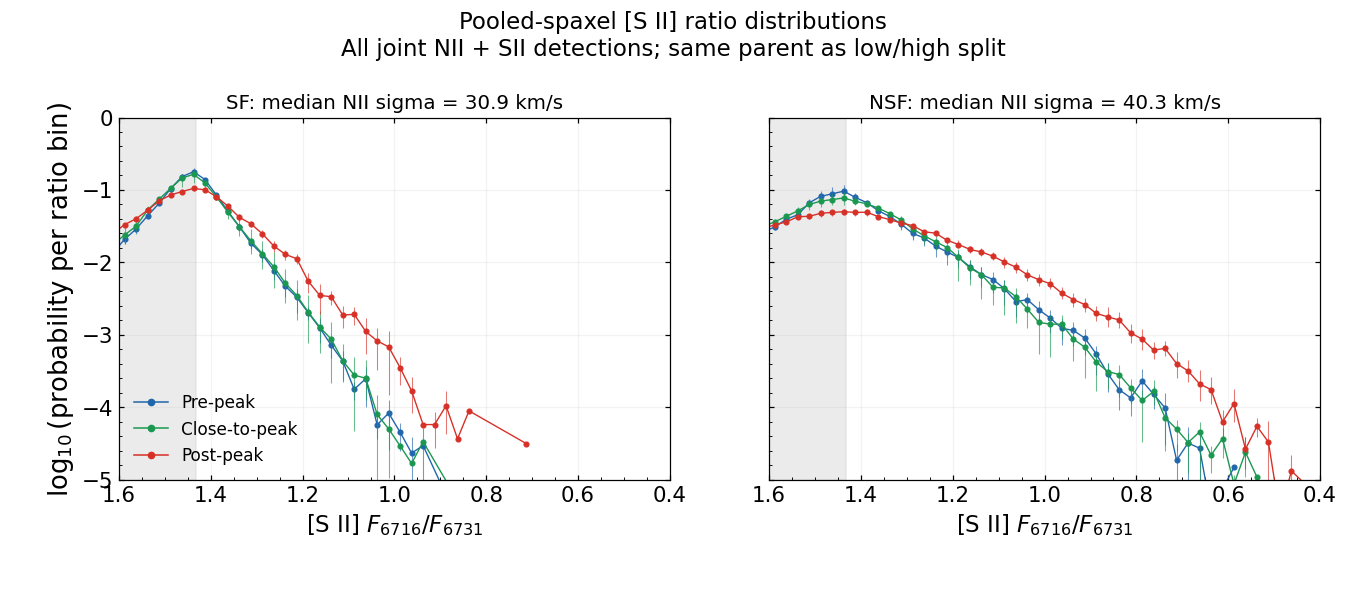

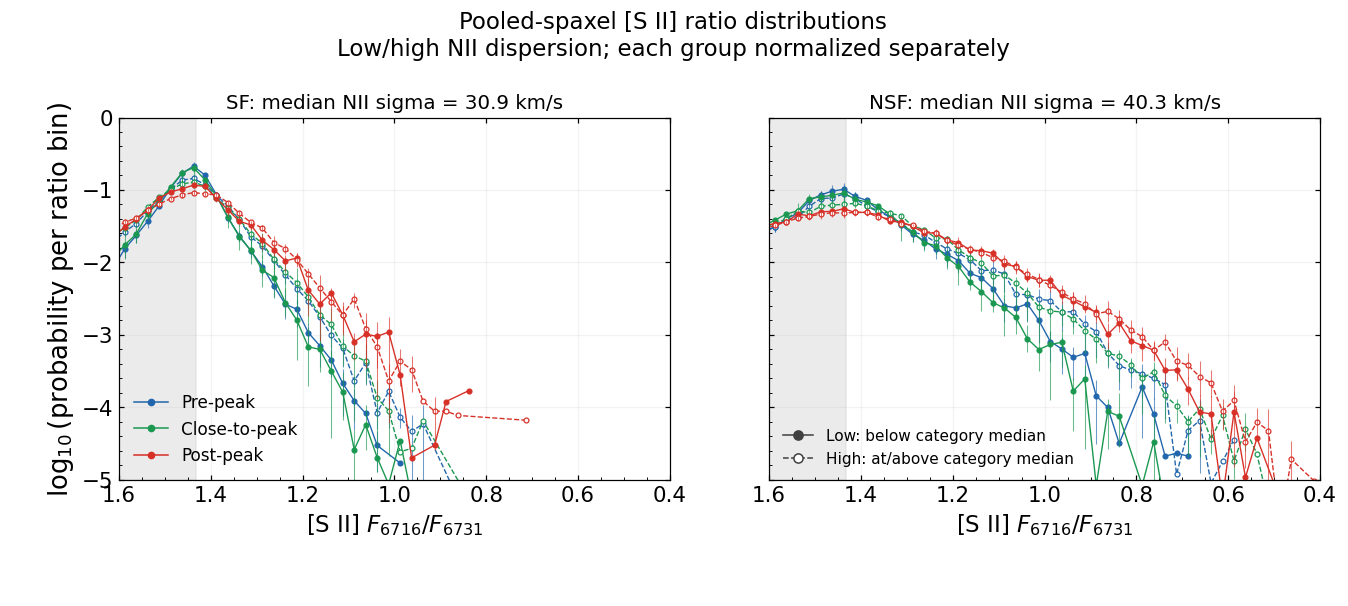

In [9]:
plot_dispersion_split('pooled_spaxel')

## Interpretation checks

- Compare low/high shapes within each SF/NSF panel and stage, then inspect the
  joint-sample counts and product support. A difference in pooled curves alone
  may be driven by products with many detected spaxels.
- SF and NSF use different empirical velocity thresholds. Low SF and low NSF
  do not represent the same absolute dispersion range. The median is pooled
  over spaxels, so large products influence its location even in equal-galaxy plots.
- Check how many valid NII measurements lack SII detections. Doublet detection
  can change the selected distributions and the relative low/high counts.
- Radius, stellar surface density, S/N, beam smearing and line-fit uncertainty
  are not matched by this split. SF is itself selected using Halpha dispersion.
  A trend here is an association within the selection, not identification of
  an ionising source or proof of a causal density-dispersion relation.
- No formal low/high significance test or electron-density inversion is made.
  Product bootstrap bars describe sample variation conditional on fixed medians;
  they do not include measurement uncertainty in either diagnostic.